LibsndfileError: Error opening 'dataset/hai/hai_01.wav': System error.

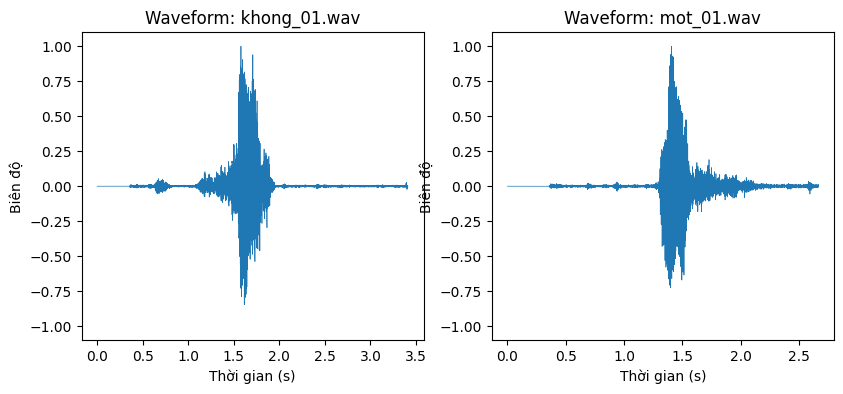

In [5]:
import numpy as np
import librosa
import matplotlib.pyplot as plt

# --- Bước 1: Khai báo siêu tham số (Hyperparameters) ---
FS = 16000
FRAME_MS, HOP_MS = 25, 10
WIN = int(FS * FRAME_MS / 1000)  # 400 mẫu
HOP = int(FS * HOP_MS / 1000)    # 160 mẫu

# --- Bước 2: Viết hàm đọc và chuẩn hóa âm thanh ---
def load_audio(path):
    # Đọc file, ép về tần số chuẩn 16 kHz và dạng mono
    y, sr = librosa.load(path, sr=FS, mono=True)
    # Chuẩn hóa biên độ lớn nhất về mức 1.0 (tránh xén đỉnh)
    y = y / (np.max(np.abs(y)) + 1e-9)
    return y

# --- Bước 3: Vẽ kiểm tra waveform của ít nhất 3 từ ---
# (Lưu ý: Đổi tên file wav và thư mục trùng khớp với cấu trúc bạn đang lưu)
files_to_check = [
    'dataset/khong/khong_01.wav', 
    'dataset/mot/mot_01.wav', 
    'dataset/hai/hai_01.wav'
]

plt.figure(figsize=(15, 4))
for i, path in enumerate(files_to_check):
    y = load_audio(path)
    # Tạo trục thời gian tương ứng với số mẫu âm thanh
    time_axis = np.linspace(0, len(y)/FS, num=len(y))
    
    plt.subplot(1, 3, i+1)
    plt.plot(time_axis, y, linewidth=0.5)
    plt.title(f"Waveform: {path.split('/')[-1]}")
    plt.xlabel("Thời gian (s)")
    plt.ylabel("Biên độ")
    plt.ylim(-1.1, 1.1)

plt.tight_layout()
plt.show()

In [4]:
import os
print("Thư mục đang chạy code:", os.getcwd())
print("File có tồn tại không?:", os.path.exists('dataset/khong/khong_01.wav'))

Thư mục đang chạy code: c:\Lab_2351260641_NguyenQuocBao\Lab02_2351260641_NguyenQuocBao
File có tồn tại không?: True
